In [1]:
#import libraries
import pandas as pd
import numpy as np

In [2]:
#load the dataset
dataset = pd.read_csv('diabetes_health_indicators.csv')

In [3]:
#Checking the first 5 rows of the dataset
pd.set_option('display.max_columns', None)
dataset.head(5)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,0,0,0,0,1,0,1,0,5,18,15,1,0,9,4,3
1,0,0,0,0,25,1,0,0,1,0,0,0,0,1,3,0,0,0,0,7,6,1
2,0,1,1,1,28,0,0,0,0,1,0,0,1,1,5,30,30,1,0,9,4,8
3,0,1,0,1,27,0,0,0,1,1,1,0,1,0,2,0,0,0,0,11,3,6
4,0,1,1,1,24,0,0,0,1,1,1,0,1,0,2,3,0,0,0,11,5,4


In [4]:
#checking the shape of the dataset
dataset.shape

(253680, 22)

In [5]:
#checking the information of the dataset
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Diabetes_012          253680 non-null  int64
 1   HighBP                253680 non-null  int64
 2   HighChol              253680 non-null  int64
 3   CholCheck             253680 non-null  int64
 4   BMI                   253680 non-null  int64
 5   Smoker                253680 non-null  int64
 6   Stroke                253680 non-null  int64
 7   HeartDiseaseorAttack  253680 non-null  int64
 8   PhysActivity          253680 non-null  int64
 9   Fruits                253680 non-null  int64
 10  Veggies               253680 non-null  int64
 11  HvyAlcoholConsump     253680 non-null  int64
 12  AnyHealthcare         253680 non-null  int64
 13  NoDocbcCost           253680 non-null  int64
 14  GenHlth               253680 non-null  int64
 15  MentHlth              253680 non-null  int64


In [6]:
#checking the value counts in the dataset
print(dataset["Diabetes_012"].value_counts())

Diabetes_012
0    213703
2     35346
1      4631
Name: count, dtype: int64


### Target Conversion: Why Binary?

**Decision:** I converted `Diabetes_012` (0 = none, 1 = prediabetes, 2 = diabetes) into a binary target, `Diabetes_binary` (1 = diabetes, 0 = everything else).

**Reasons:**
- Prediabetes is a very small class (about 2% of rows), so a 3-class model would rarely predict it and its metrics would be unstable.
- The project is a yes/no risk flag for a nurse or case manager, so a binary target fits the use case.
- A binary target allows the standard imbalanced-classification metrics: recall, precision, F1, PR-AUC and ROC-AUC.

**Trade-off:** prediabetes patients are grouped with "no diabetes", so the model cannot flag them as at-risk. I accept this to keep the problem clean and the evaluation reliable.

**Cleanup:** `Diabetes_012` is dropped after conversion so it cannot leak the answer into the features.

In [7]:
dataset["Diabetes_binary"] = (dataset["Diabetes_012"] == 2).astype(int)
dataset = dataset.drop(columns=["Diabetes_012"])
print(dataset["Diabetes_binary"].value_counts())
print(dataset["Diabetes_binary"].value_counts(normalize=True).round(4))

Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64
Diabetes_binary
0    0.8607
1    0.1393
Name: proportion, dtype: float64


In [8]:
dataset.head(5)

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,0,1,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,0,0,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,0,1,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,0,1,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,0,1,0,2,3,0,0,0,11,5,4,0


In [9]:
# How many duplicate rows?
print(dataset.duplicated().sum())
print(round(dataset.duplicated().mean() * 100, 2), "%")

24206
9.54 %


In [10]:
dups = dataset[dataset.duplicated(keep=False)]
print(len(dups))
print(dups["Diabetes_binary"].value_counts(normalize=True).round(4))
print(dataset["Diabetes_binary"].value_counts(normalize=True).round(4))

35575
Diabetes_binary
0    0.9865
1    0.0135
Name: proportion, dtype: float64
Diabetes_binary
0    0.8607
1    0.1393
Name: proportion, dtype: float64


In [11]:
before = len(dataset)
dataset = dataset.drop_duplicates().reset_index(drop=True)
print(before, "->", len(dataset))
print(dataset["Diabetes_binary"].value_counts())
print(dataset["Diabetes_binary"].value_counts(normalize=True).round(4))

253680 -> 229474
Diabetes_binary
0    194377
1     35097
Name: count, dtype: int64
Diabetes_binary
0    0.8471
1    0.1529
Name: proportion, dtype: float64


After removal the dataset has 229,474 rows. The class split changed from 86.07% / 13.93% to 84.71% / 15.29% (194,377 non-diabetic, 35,097 diabetic).

In [12]:
print(dataset.shape)                # expect (229474, 22)
print(dataset.duplicated().sum())   # expect 0

(229474, 22)
0


Diabetes_binary
0    194377
1     35097
Name: count, dtype: int64
Diabetes_binary
0    0.8471
1    0.1529
Name: proportion, dtype: float64
Imbalance ratio: 5.54


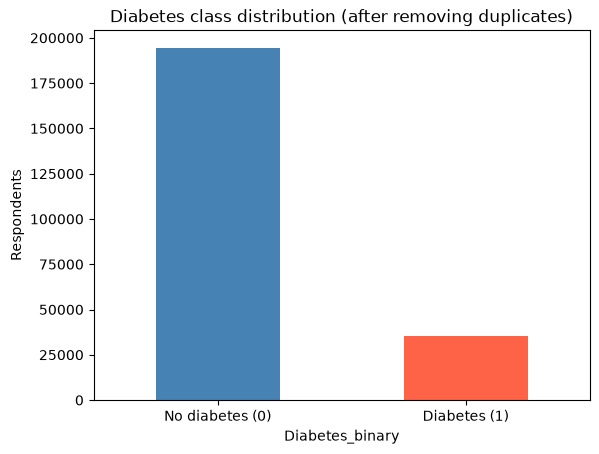

In [13]:
import matplotlib.pyplot as plt

counts = dataset["Diabetes_binary"].value_counts().sort_index()
print(counts)
print(dataset["Diabetes_binary"].value_counts(normalize=True).round(4))
print("Imbalance ratio:", round(counts[0] / counts[1], 2))

counts.plot(kind="bar", color=["steelblue", "tomato"])
plt.xticks([0, 1], ["No diabetes (0)", "Diabetes (1)"], rotation=0)
plt.title("Diabetes class distribution (after removing duplicates)")
plt.ylabel("Respondents")
plt.show()

### Finding: Class Balance

After removing duplicates, the target is imbalanced: 194,377 respondents without diabetes (84.71%) and 35,097 with diabetes (15.29%), a ratio of about 5.5 to 1. Accuracy alone would be misleading, so I will use a stratified split, balance the training set only, and keep the test set at its natural ratio. On that test set I will report recall, precision, F1, PR-AUC and ROC-AUC, plus a confusion matrix for the final model.

In [14]:
print(dataset.isnull().sum())
print("Total missing:", dataset.isnull().sum().sum())

HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Diabetes_binary         0
dtype: int64
Total missing: 0


In [15]:
missing = dataset.isnull().sum()
print(missing[missing > 0])

Series([], dtype: int64)


In [16]:
dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
HighBP,229474.0,0.454343,0.497912,0.0,0.0,0.0,1.0,1.0
HighChol,229474.0,0.441640,0.496584,0.0,0.0,0.0,1.0,1.0
CholCheck,229474.0,0.959481,0.197173,0.0,1.0,1.0,1.0,1.0
BMI,229474.0,28.687507,6.789204,12.0,24.0,27.0,32.0,98.0
Smoker,229474.0,0.465800,0.498830,0.0,0.0,0.0,1.0,1.0
Stroke,229474.0,0.044816,0.206899,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,229474.0,0.103336,0.304398,0.0,0.0,0.0,0.0,1.0
PhysActivity,229474.0,0.733042,0.442371,0.0,0.0,1.0,1.0,1.0
Fruits,229474.0,0.612675,0.487140,0.0,0.0,1.0,1.0,1.0
Veggies,229474.0,0.794587,0.404004,0.0,1.0,1.0,1.0,1.0


### Value Ranges

All columns fall within their expected ranges: binary columns 0 to 1, `GenHlth` 1 to 5, `Age` 1 to 13 (age bands), `Education` 1 to 6, `Income` 1 to 8, and `MentHlth` and `PhysHlth` 0 to 30 days. No placeholder or impossible values were found.

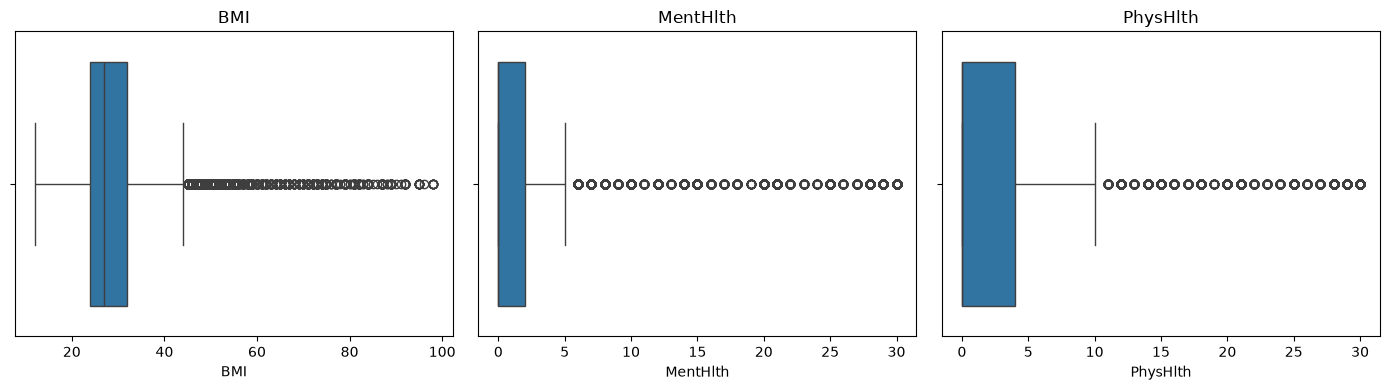

BMI IQR bounds: 12.0 44.0
BMI outliers: 5638 (2.46%)
BMI max: 98


In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Boxplots for the three numeric-style columns
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["BMI", "MentHlth", "PhysHlth"]):
    sns.boxplot(x=dataset[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# IQR bounds and outlier count for BMI
Q1, Q3 = dataset["BMI"].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
n_out = ((dataset["BMI"] < lower) | (dataset["BMI"] > upper)).sum()

print("BMI IQR bounds:", lower, upper)
print("BMI outliers:", n_out, f"({n_out / len(dataset) * 100:.2f}%)")
print("BMI max:", dataset["BMI"].max())

In [18]:
print((dataset["BMI"] > 60).sum())
print((dataset["BMI"] > 80).sum())
print(dataset["BMI"].quantile([0.99, 0.999]))

805
279
0.990    50.000
0.999    81.527
Name: BMI, dtype: float64


In [19]:
dataset["BMI"] = dataset["BMI"].clip(upper=60)
print(dataset["BMI"].describe())
print((dataset["BMI"] > 60).sum())   # expect 0

count    229474.000000
mean         28.631401
std           6.432383
min          12.000000
25%          24.000000
50%          27.000000
75%          32.000000
max          60.000000
Name: BMI, dtype: float64
0


### Outliers

BMI has 5,638 values (2.46%) above the IQR upper bound of 44 (lower bound 12; max 98). Most of these are plausible real values, since high BMI is a known diabetes risk factor, so I kept the rows. However, 805 rows (0.35%) have BMI above 60 and 279 (0.12%) are above 80, and the jump from the 99th percentile (50) to the 99.9th (81.5) suggests a small cluster of implausible self-reported values. I capped BMI at 60 (a fixed medical cutoff, not data-derived, so no train/test leakage) instead of deleting rows. `MentHlth` and `PhysHlth` are heavily skewed, with most respondents at 0 and a cluster at 30, which reflects how the survey question works, not bad data. Tree-based models are robust to outliers.

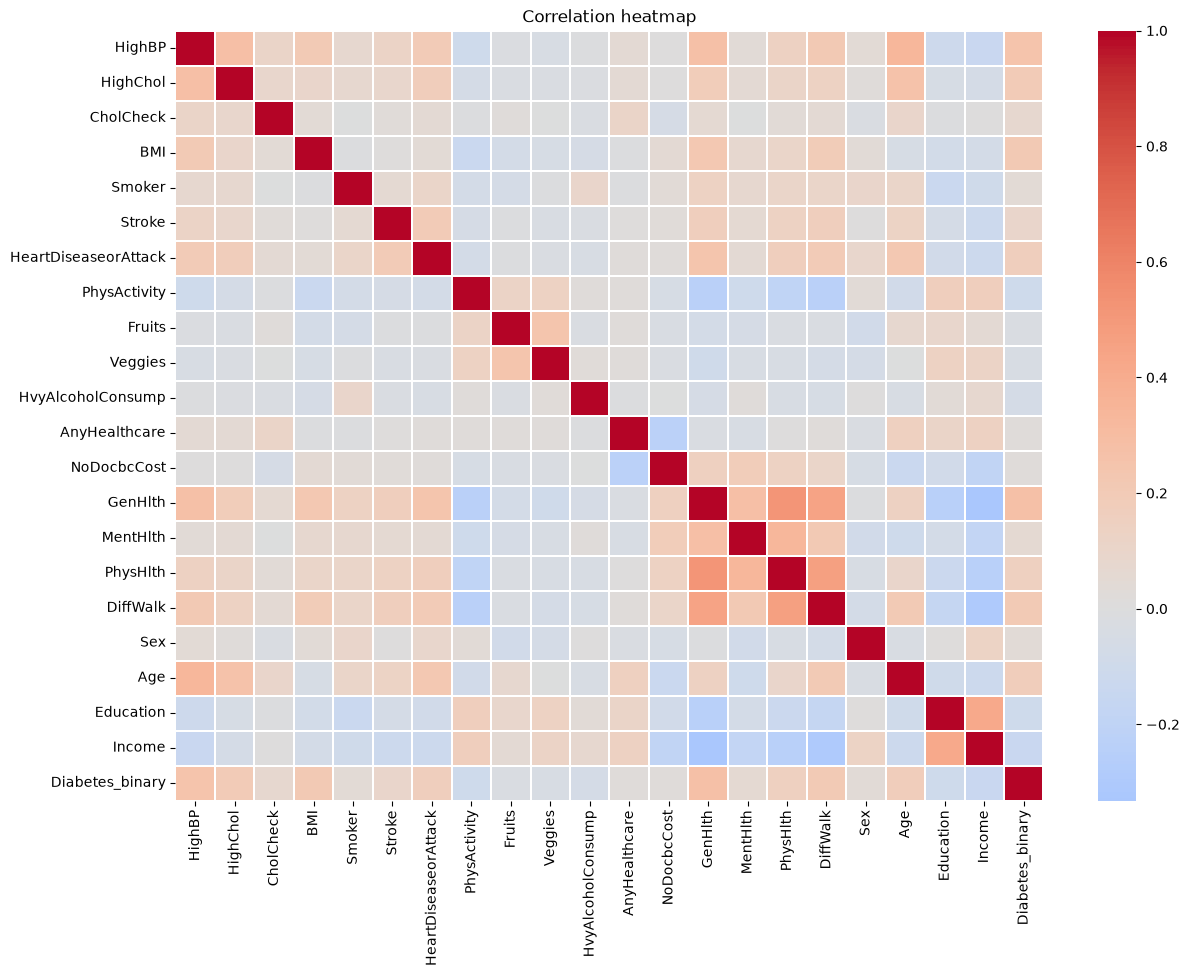

GenHlth                 0.277
HighBP                  0.254
BMI                     0.216
DiffWalk                0.205
HighChol                0.195
Age                     0.177
HeartDiseaseorAttack    0.168
PhysHlth                0.156
Income                 -0.141
Education              -0.103
PhysActivity           -0.100
Stroke                  0.099
CholCheck               0.073
HvyAlcoholConsump      -0.066
MentHlth                0.054
Smoker                  0.046
Veggies                -0.042
Sex                     0.033
AnyHealthcare           0.025
Fruits                 -0.025
NoDocbcCost             0.020
Name: Diabetes_binary, dtype: float64


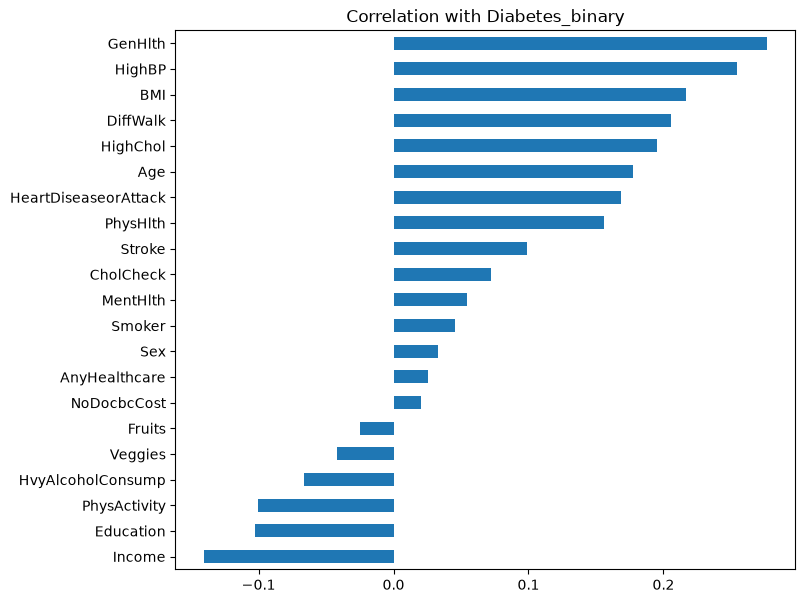

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# Full correlation heatmap
corr = dataset.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Correlation heatmap")
plt.show()

# Each feature's correlation with the target, strongest first
target_corr = corr["Diabetes_binary"].drop("Diabetes_binary").sort_values(key=abs, ascending=False)
print(target_corr.round(3))

target_corr.sort_values().plot(kind="barh", figsize=(8, 7))
plt.title("Correlation with Diabetes_binary")
plt.show()

### Correlation Analysis

The strongest correlations with `Diabetes_binary` are `GenHlth` (0.277), `HighBP` (0.254), `BMI` (0.216), `DiffWalk` (0.205), `HighChol` (0.195), `Age` (0.177), `HeartDiseaseorAttack` (0.168) and `PhysHlth` (0.156). `Income` (-0.141), `Education` (-0.103) and `PhysActivity` (-0.100) are negatively correlated, so higher values go with lower diabetes rates. No feature has a correlation above 0.3, so no single variable predicts the target on its own. Several features are very weakly correlated (`AnyHealthcare` 0.025, `Fruits` -0.025, `NoDocbcCost` 0.020). The negative sign on `HvyAlcoholConsump` is a known survey artefact, not a protective effect. Correlation measures linear association only, so these weak features are not dropped on this evidence alone.

In [21]:
corr_feat = dataset.drop(columns=["Diabetes_binary"]).corr().abs()
pairs = corr_feat.where(~np.tril(np.ones(corr_feat.shape)).astype(bool)).stack()
print(pairs[pairs > 0.5].sort_values(ascending=False))

GenHlth  PhysHlth    0.516476
dtype: float64


### Feature Decisions

I checked pairwise correlations between features. Only one pair exceeds 0.5: `GenHlth` and `PhysHlth` (0.516), which is expected since people who rate their health poorly also report more unwell days. This is mild and below the level that causes problems for Logistic Regression, and tree-based models are unaffected, so I kept both. No other pair is above 0.5, so there is no serious multicollinearity.

All 21 features are kept for the first round of training, since the dataset is large (229,474 rows) and weak features do little harm to tree models. After training, I will compare the full model against one without the weakest features (`AnyHealthcare`, `NoDocbcCost`, `Fruits`, `Veggies`, `Sex`, `Smoker`, `MentHlth`) and use the smaller set if scores barely change, which would also give a shorter input form in the web app.

In [22]:
from sklearn.model_selection import train_test_split

X = dataset.drop(columns=["Diabetes_binary"])
y = dataset["Diabetes_binary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(4))
print(y_test.value_counts(normalize=True).round(4))

(183579, 21) (45895, 21)
Diabetes_binary
0    0.8471
1    0.1529
Name: proportion, dtype: float64
Diabetes_binary
0    0.8471
1    0.1529
Name: proportion, dtype: float64


### Handling Class Imbalance

The target is about 85% / 15%. I balance **only the training set** with random undersampling, which removes majority-class rows until both classes are equal. The test set is left at its natural ratio, so the evaluation reflects what the app will see in real use. Undersampling suits this dataset because even after it, tens of thousands of rows remain, and it avoids creating synthetic records.

In [23]:
from imblearn.under_sampling import RandomUnderSampler

# Balance the TRAINING data only. X_test and y_test are never touched.
rus = RandomUnderSampler(random_state=42)
X_train_bal, y_train_bal = rus.fit_resample(X_train, y_train)

print("Before balancing:", y_train.value_counts().to_dict())
print("After balancing: ", y_train_bal.value_counts().to_dict())
print("Test set (unchanged):", y_test.value_counts().to_dict())

Before balancing: {0: 155501, 1: 28078}
After balancing:  {0: 28078, 1: 28078}
Test set (unchanged): {0: 38876, 1: 7019}


Training set before balancing: 155,501 no diabetes / 28,078 diabetes. After undersampling: 28,078 / 28,078 (50/50). The test set stays at its natural ratio (38,876 / 7,019).

### Model Training and Comparison

I train three models on the balanced training set and evaluate all of them on the untouched test set: Logistic Regression (interpretable baseline, with feature scaling), Random Forest and XGBoost (non-linear models that usually do best on tabular data).

**Metrics reported:** recall, precision, F1, ROC-AUC and PR-AUC, plus a confusion matrix for the final model. Recall is the priority, because for a risk flag a missed diabetic person costs more than a false alarm.

**Why accuracy is not reported:** the test set is imbalanced (about 85% no diabetes, 15% diabetes). A model that predicts "no diabetes" for everyone would score about 85% accuracy while catching none of the diabetic respondents, so accuracy would hide the errors that matter.

In [24]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score)

# Scaling only matters for Logistic Regression, so it goes in a pipeline.
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.1,
        eval_metric="logloss", n_jobs=-1, random_state=42),
}

results = []
fitted = {}   # keep trained models for the confusion matrix and saving

for name, model in models.items():
    model.fit(X_train_bal, y_train_bal)          # train on balanced data
    pred = model.predict(X_test)                 # evaluate on natural test set
    proba = model.predict_proba(X_test)[:, 1]    # probability of diabetes

    results.append({
        "Model": name,
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
    })
    fitted[name] = model

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df.sort_values("Recall", ascending=False)

,Recall,Precision,F1,ROC-AUC,PR-AUC
Model,,,,,
XGBoost,0.791,0.314,0.449,0.817,0.437
Random Forest,0.785,0.315,0.449,0.814,0.429
Logistic Regression,0.760,0.320,0.450,0.811,0.421


### Model Comparison Results

| Model | Recall | Precision | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.760 | 0.320 | 0.450 | 0.811 | 0.421 |
| Random Forest | 0.785 | 0.315 | 0.449 | 0.814 | 0.429 |
| XGBoost | 0.791 | 0.314 | 0.449 | 0.817 | 0.437 |

**Observation:** XGBoost is best on recall (0.791), ROC-AUC (0.817) and PR-AUC (0.437). Its recall is 3.1 points higher than Logistic Regression (0.760) and 0.6 points higher than Random Forest (0.785). Precision and F1 are almost identical across the three models (precision 0.314 to 0.320, F1 0.449 to 0.450), so the models differ mainly in how many diabetic cases they catch. The overall gap between models is small, which suggests the features, not the algorithm, set the ceiling on performance.

**Note on precision:** precision is lower than recall because the models were trained on balanced data but tested on data with only about 15% positives, so the models flag more people than the natural rate would suggest. This is an expected trade-off of balancing, not a bug.

### Model Selection: XGBoost

**Decision:** I ship XGBoost as the final model for Project 2.

**Justification:**
- **Highest recall (0.791).** For a first-pass risk flag, a missed diabetic respondent costs more than a false alarm, so recall is the priority metric. XGBoost catches about 3 more diabetic cases per 100 than Logistic Regression (0.760) and slightly more than Random Forest (0.785).
- **Highest ROC-AUC (0.817) and PR-AUC (0.437).** These are threshold-independent, so they show XGBoost ranks risky respondents above healthy ones better than the other two. PR-AUC matters most here because the test set is imbalanced (about 15% positive).
- **Precision and F1 are essentially tied** (precision 0.314 to 0.320, F1 0.449 to 0.450), so XGBoost gains recall without a meaningful loss elsewhere.
- **Provides `predict_proba`**, so the app can show a risk score and pass it to the Gen AI layer.

**Caveats:**
- The gap between models is small (0.006 ROC-AUC against Logistic Regression), which suggests the features, not the algorithm, limit performance. Logistic Regression would be a reasonable choice for interpretability, but XGBoost is better on the metrics that matter for this use case.
- Precision is about 0.31, so roughly 1 in 3 flagged respondents actually has diabetes. This is acceptable for a first-pass flag for a nurse or case manager, but it is a flag, not a diagnosis.
- The original dataset is imbalanced (about 85% / 15%), and the test set keeps that natural ratio. Only the training set was undersampled to 50/50. Because the model learned from balanced data, its predicted probabilities overstate real-world risk, so the app presents the output as a "risk score", not a literal probability.

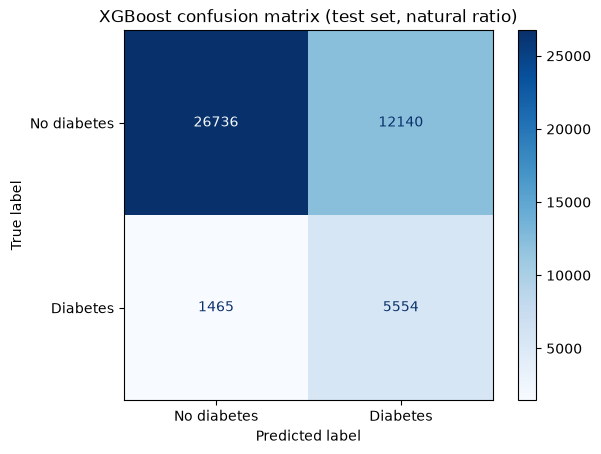

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_model = fitted["XGBoost"]
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test,
    display_labels=["No diabetes", "Diabetes"], cmap="Blues")
plt.title("XGBoost confusion matrix (test set, natural ratio)")
plt.show()

### Confusion Matrix: XGBoost (test set, natural ratio)

Out of 45,895 test respondents:
- **True positives: 5,554** diabetic respondents correctly flagged
- **False negatives: 1,465** diabetic respondents the model missed (20.9% of all 7,019 diabetic cases)
- **False positives: 12,140** non-diabetic respondents flagged by mistake
- **True negatives: 26,736** non-diabetic respondents correctly cleared

The model catches about 79% of diabetic respondents (recall 0.791). The cost is a high number of false alarms: about 69% of flagged respondents do not have diabetes (precision 0.314). For a first-pass flag reviewed by a nurse or case manager, I accept this trade-off, because a missed diabetic person costs more than an extra check. The result is a risk flag, not a diagnosis.

In [26]:
import joblib
joblib.dump(best_model, "xgb_diabetes_model.pkl")
joblib.dump(list(X.columns), "diabetes_feature_columns.pkl")

['diabetes_feature_columns.pkl']

In [1]:
import xgboost, sklearn
print(xgboost.__version__, sklearn.__version__)

3.4.1 1.9.0
